# Logistic Regression & Log-Loss — Pass/Fail Workshop

**Independent implementation | Foundations of Machine Learning**

This notebook uses the **same 19 study-hours / pass-fail observations** as the instructor's workshop. The goal is to train a logistic regression classifier, implement binary cross-entropy (Log-Loss) manually, and inspect its results.

**Labels:** `0 = Fail`, `1 = Pass`. This is a small teaching dataset, not a reliable prediction tool for real students.

## 1. Import libraries and load the workshop data

In [2]:
# Libraries for calculations, graphs, the classification model, and validation.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss as sklearn_log_loss, accuracy_score

# Reuse the same observations from the instructor's original notebook.
hours = np.array([0.5, 0.75, 1, 1.25, 1.5, 1.75, 2, 2.25, 2.5,
                  2.75, 3, 3.25, 3.5, 3.75, 4, 4.25, 4.5, 4.75, 5])
labels = np.array([0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1])

# Scikit-learn expects a 2D array of input features.
X = hours.reshape(-1, 1)
y = labels

data = pd.DataFrame({'Hours Studied': hours, 'Actual Result': labels})
display(data)

,Hours Studied,Actual Result
0,0.50,0
1,0.75,0
2,1.00,0
3,1.25,0
4,1.50,0
5,1.75,0
6,2.00,0
7,2.25,0
8,2.50,1
9,2.75,0


## 2. Train Logistic Regression and estimate probabilities

The model predicts the probability of `Pass = 1`. A probability of at least 0.5 is classified as Pass.

In [3]:
# Fit the classifier to the example observations.
model = LogisticRegression()
model.fit(X, y)

# predict_proba returns two columns: probability of Fail and Pass.
pass_probabilities = model.predict_proba(X)[:, 1]
predicted_labels = (pass_probabilities >= 0.5).astype(int)

results = data.copy()
results['P(Pass)'] = np.round(pass_probabilities, 4)
results['Predicted Result'] = predicted_labels
display(results)
print(f"Training accuracy: {accuracy_score(y, predicted_labels):.3f}")

,Hours Studied,Actual Result,P(Pass),Predicted Result
0,0.50,0,0.0234,0
1,0.75,0,0.0342,0
2,1.00,0,0.0498,0
3,1.25,0,0.0720,0
4,1.50,0,0.1029,0
5,1.75,0,0.1451,0
6,2.00,0,0.2008,0
7,2.25,0,0.2710,0
8,2.50,1,0.3549,0
9,2.75,0,0.4488,0


Training accuracy: 0.895


## 3. Implement binary Log-Loss from scratch

For each observation, the loss is $-[y\log(p)+(1-y)\log(1-p)]$. The overall loss is the **mean** across observations. We clip probabilities to avoid calculating $\log(0)$.

In [4]:
def binary_log_loss(y_true, y_prob):
    """Return the average binary cross-entropy loss for labels 0/1."""
    # Convert inputs into arrays and verify their dimensions.
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob, dtype=float)
    if y_true.shape != y_prob.shape or y_true.ndim != 1:
        raise ValueError('Labels and probabilities must be 1D arrays of equal length.')
    if len(y_true) == 0 or not np.all(np.isin(y_true, [0, 1])):
        raise ValueError('Labels must be a nonempty array containing only 0 and 1.')
    if not np.all(np.isfinite(y_prob)) or np.any((y_prob < 0) | (y_prob > 1)):
        raise ValueError('Probabilities must be finite numbers between 0 and 1.')

    # Prevent undefined logarithms when a probability is exactly 0 or 1.
    eps = 1e-15
    p = np.clip(y_prob, eps, 1 - eps)

    # Calculate the loss for each observation, then take the mean.
    individual_losses = -(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))
    return float(np.mean(individual_losses))

manual_loss = binary_log_loss(y, pass_probabilities)
library_loss = sklearn_log_loss(y, pass_probabilities, labels=[0, 1])
print(f'Manual Log-Loss: {manual_loss:.6f}')
print(f'Scikit-learn Log-Loss: {library_loss:.6f}')
print(f'Difference: {abs(manual_loss - library_loss):.10f}')
assert np.isclose(manual_loss, library_loss), 'The two calculations should match.' 

Manual Log-Loss: 0.275395
Scikit-learn Log-Loss: 0.275395
Difference: 0.0000000000


## 4. Explore individual losses

Confident wrong predictions receive larger penalties. The table shows which observations contribute the most loss.

In [5]:
# Calculate loss per student using the same formula as our function.
p = np.clip(pass_probabilities, 1e-15, 1 - 1e-15)
individual_losses = -(y * np.log(p) + (1 - y) * np.log(1 - p))
results['Individual Log-Loss'] = np.round(individual_losses, 4)
display(results.sort_values('Individual Log-Loss', ascending=False))

,Hours Studied,Actual Result,P(Pass),Predicted Result,Individual Log-Loss
8,2.50,1,0.3549,0,1.0359
11,3.25,0,0.6406,1,1.0234
10,3.00,1,0.5464,1,0.6044
9,2.75,0,0.4488,0,0.5956
12,3.50,1,0.7251,1,0.3214
7,2.25,0,0.2710,0,0.3161
13,3.75,1,0.7961,1,0.2281
6,2.00,0,0.2008,0,0.2241
14,4.00,1,0.8524,1,0.1597
5,1.75,0,0.1451,0,0.1568


## 5. Visualize predicted probabilities and loss

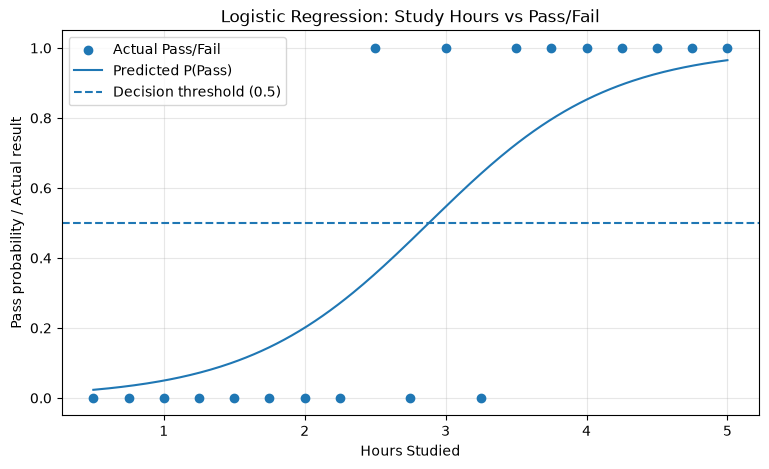

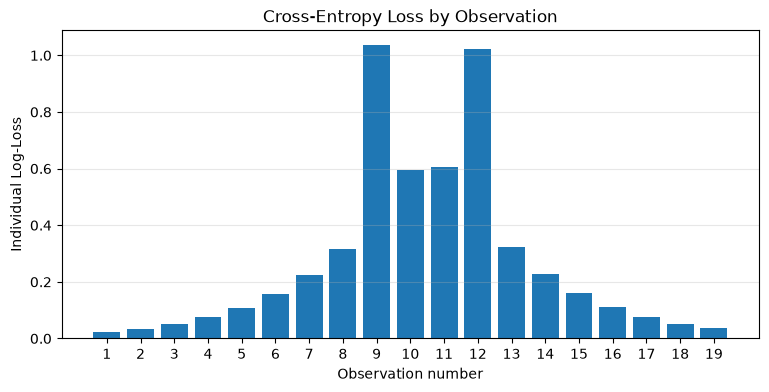

In [6]:
# Plot the predicted probability curve and the actual outcomes.
hours_grid = np.linspace(hours.min(), hours.max(), 250).reshape(-1, 1)
probability_curve = model.predict_proba(hours_grid)[:, 1]

plt.figure(figsize=(9, 5))
plt.scatter(hours, y, label='Actual Pass/Fail', zorder=3)
plt.plot(hours_grid.ravel(), probability_curve, label='Predicted P(Pass)')
plt.axhline(0.5, linestyle='--', label='Decision threshold (0.5)')
plt.xlabel('Hours Studied')
plt.ylabel('Pass probability / Actual result')
plt.title('Logistic Regression: Study Hours vs Pass/Fail')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Plot the loss of each observation to highlight difficult predictions.
plt.figure(figsize=(9, 4))
plt.bar(np.arange(1, len(y) + 1), individual_losses)
plt.xlabel('Observation number')
plt.ylabel('Individual Log-Loss')
plt.title('Cross-Entropy Loss by Observation')
plt.xticks(np.arange(1, len(y) + 1))
plt.grid(axis='y', alpha=0.3)
plt.show()

## 6. Test the loss function with simple examples

In [7]:
# Compare a confident correct prediction with a confident incorrect one.
examples = [
    ('Correct, confident Pass', np.array([1]), np.array([0.95])),
    ('Incorrect, confident Pass', np.array([0]), np.array([0.95])),
    ('Uncertain prediction', np.array([1]), np.array([0.50])),
]
for description, actual, probability in examples:
    print(f'{description}: {binary_log_loss(actual, probability):.4f}')

print(f'\nOverall training Log-Loss: {manual_loss:.4f}')
print('Lower Log-Loss is better when comparing probability predictions on the same data.')

Correct, confident Pass: 0.0513
Incorrect, confident Pass: 2.9957
Uncertain prediction: 0.6931

Overall training Log-Loss: 0.2754
Lower Log-Loss is better when comparing probability predictions on the same data.


## Notes and limitations

- The custom function computes **binary cross-entropy**; the logistic regression model itself is trained using scikit-learn.
- Training accuracy and training Log-Loss are measured on the **same 19 observations used to fit the model**. They are demonstrations, **not** unbiased estimates of performance on unseen students.
- The dataset comes from the instructor's `LogisticRegressionClassifier_Workshop.ipynb`.
- The peer review, talking points, GitHub submission, and PDF report are intentionally outside this code-only version.